# Microsoft AI Engineer Program via Simplilearn

### Submitted by Ronald M. Paraison

---

# Lending Club Loan Data Analysis

**Deep Learning Specialization — Course-end Project**

**Objective:** Build a deep learning model that predicts whether or not a loan will be default, using LendingClub's historical loan data (2007-2015).

**Required steps:**
1. Feature transformation — convert categorical values into numerical (discrete) values.
2. Exploratory data analysis of the different factors in the dataset.
3. Additional feature engineering — check correlation between features and drop those that are strongly correlated.
4. Modeling — build a deep learning model using Keras with TensorFlow backend.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    accuracy_score, recall_score,
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
RANDOM_STATE = 42
tf.random.set_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

## 1. Load the data

In [2]:
DATA_PATH = '/Users/paraison/Documents/MS AI Engineer Program/Deep Learning Specialization/Course End Projects/Course_End_Project_Dataset/Lending_Dataset/loan_data (2).csv'

df = pd.read_csv(DATA_PATH)
print('shape:', df.shape)
df.head()

shape: (9578, 14)


,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   str    
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), str(1)
memory usage: 1.0 MB


In [4]:
print('Null values per column:')
print(df.isnull().sum())

Null values per column:
credit.policy        0
purpose              0
int.rate             0
installment          0
log.annual.inc       0
dti                  0
fico                 0
days.with.cr.line    0
revol.bal            0
revol.util           0
inq.last.6mths       0
delinq.2yrs          0
pub.rec              0
not.fully.paid       0
dtype: int64


No missing values. `purpose` is the only non-numeric column; `not.fully.paid` is the target (1 = borrower did **not** fully repay, i.e. default).

## 2. Exploratory data analysis

not.fully.paid
0    8045
1    1533
Name: count, dtype: int64
not.fully.paid
0    83.99
1    16.01
Name: proportion, dtype: float64


/var/folders/4l/mb_q4x2x0dldnlqp1_g_sjz40000gn/T/ipykernel_8374/1400625916.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='not.fully.paid', data=df, ax=ax, palette=['#2563EB', '#EF4444'])


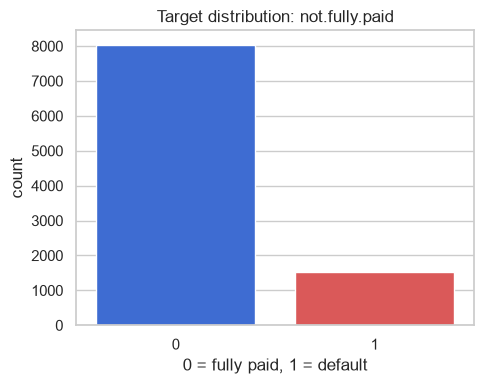

In [5]:
target_counts = df['not.fully.paid'].value_counts()
target_pct = df['not.fully.paid'].value_counts(normalize=True) * 100
print(target_counts)
print(target_pct.round(2))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x='not.fully.paid', data=df, ax=ax, palette=['#2563EB', '#EF4444'])
ax.set_title('Target distribution: not.fully.paid')
ax.set_xlabel('0 = fully paid, 1 = default')
plt.tight_layout()
plt.show()

Confirmed: the dataset is highly imbalanced — roughly 84% fully-paid vs. 16% default. This is handled later via class weighting during model training so the minority (default) class isn't drowned out.

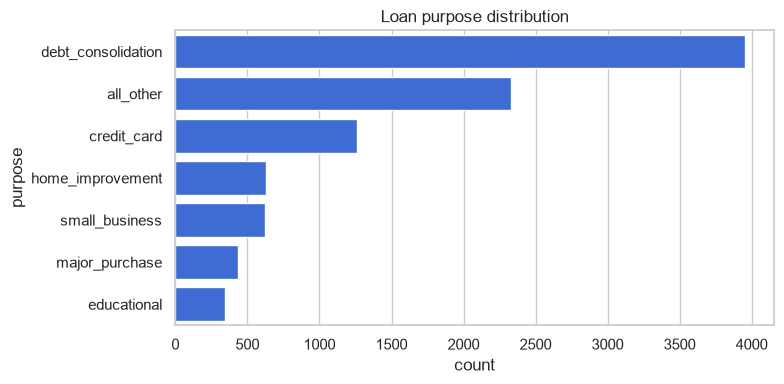

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(y='purpose', data=df, order=df['purpose'].value_counts().index, ax=ax, color='#2563EB')
ax.set_title('Loan purpose distribution')
plt.tight_layout()
plt.show()

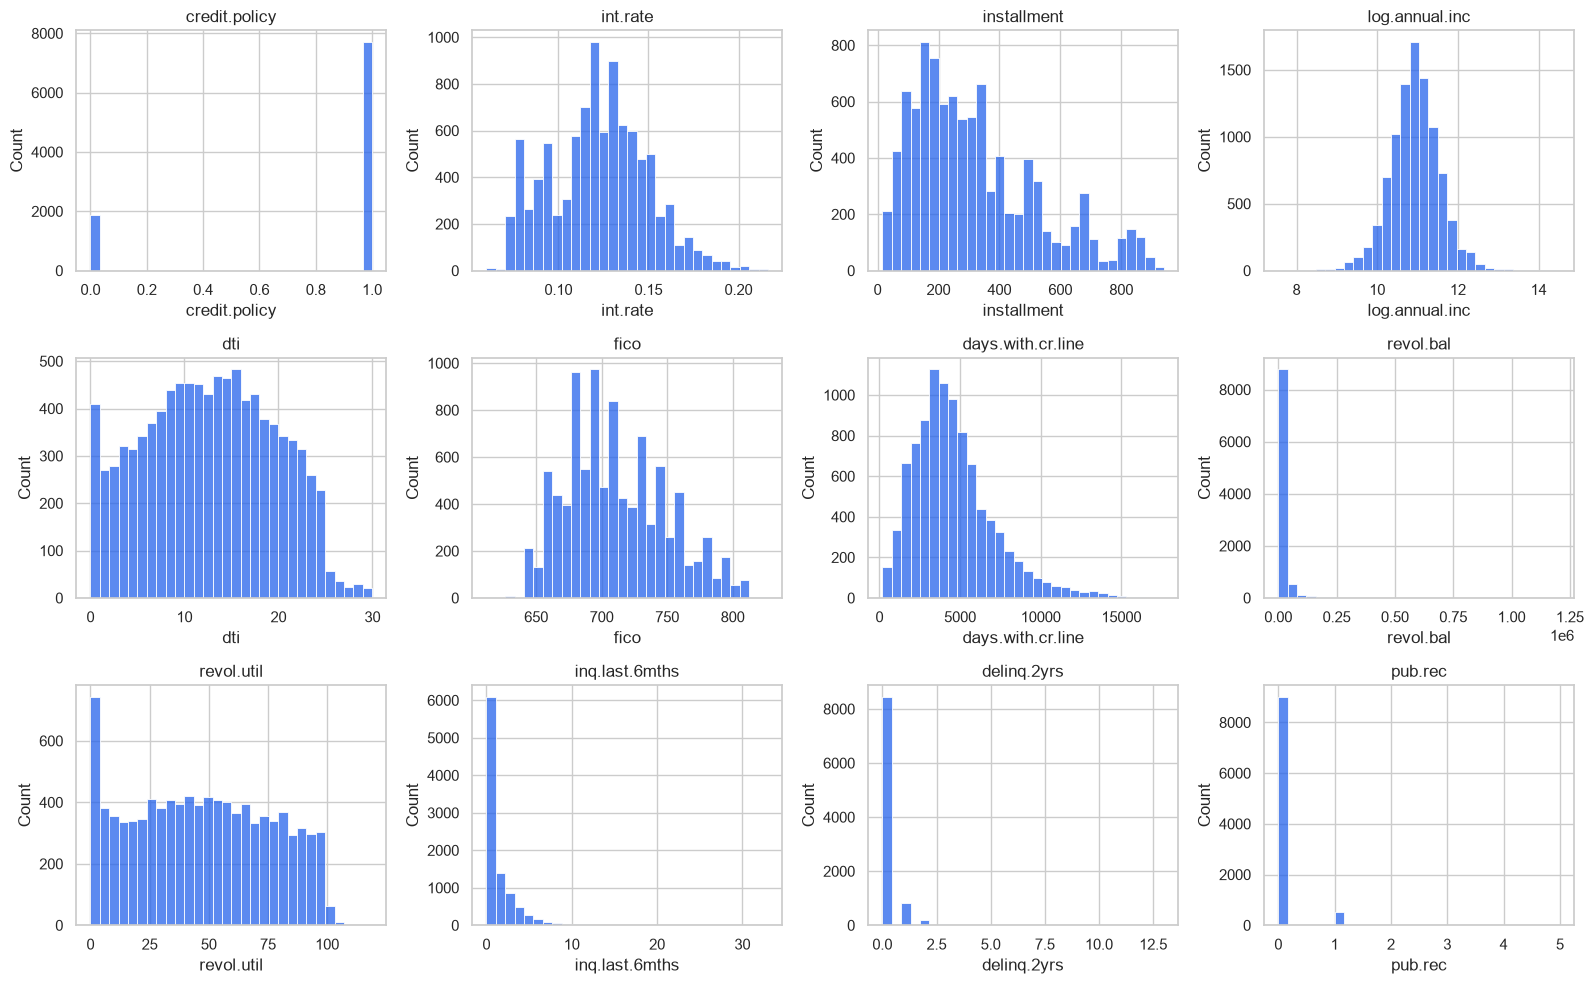

In [7]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop('not.fully.paid')

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for col, ax in zip(numeric_cols, axes.flatten()):
    sns.histplot(df[col], bins=30, ax=ax, color='#2563EB', kde=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

/var/folders/4l/mb_q4x2x0dldnlqp1_g_sjz40000gn/T/ipykernel_8374/3211462725.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='not.fully.paid', y='fico', data=df, ax=ax, palette=['#2563EB', '#EF4444'])


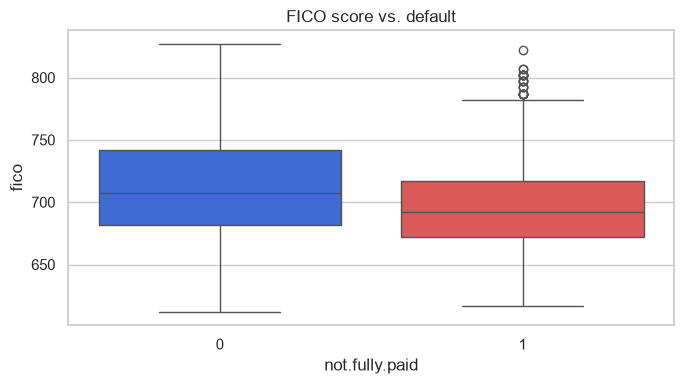

In [8]:
# How does FICO score relate to default?
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(x='not.fully.paid', y='fico', data=df, ax=ax, palette=['#2563EB', '#EF4444'])
ax.set_title('FICO score vs. default')
plt.tight_layout()
plt.show()

Borrowers who default tend to have lower FICO scores and higher interest rates — consistent with lending intuition and a good sanity check that the data is well-formed.

## 3. Feature transformation

`purpose` is the only categorical column. It has no ordinal relationship (e.g. `credit_card` isn't "more" than `educational`), so it is one-hot encoded rather than label-encoded, which avoids implying a false ordering to the model.

In [9]:
print('purpose categories:', df['purpose'].unique())

df_encoded = pd.get_dummies(df, columns=['purpose'], drop_first=True)
df_encoded = df_encoded.astype({c: int for c in df_encoded.columns if df_encoded[c].dtype == bool})
print('shape after encoding:', df_encoded.shape)
df_encoded.head()

purpose categories: <StringArray>
['debt_consolidation',        'credit_card',          'all_other',
   'home_improvement',     'small_business',     'major_purchase',
        'educational']
Length: 7, dtype: str
shape after encoding: (9578, 19)


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,1,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0,0,1,0,0,0,0
1,1,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0,1,0,0,0,0,0
2,1,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0,0,1,0,0,0,0
3,1,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0,0,1,0,0,0,0
4,1,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0,1,0,0,0,0,0


## 4. Additional feature engineering — correlation analysis

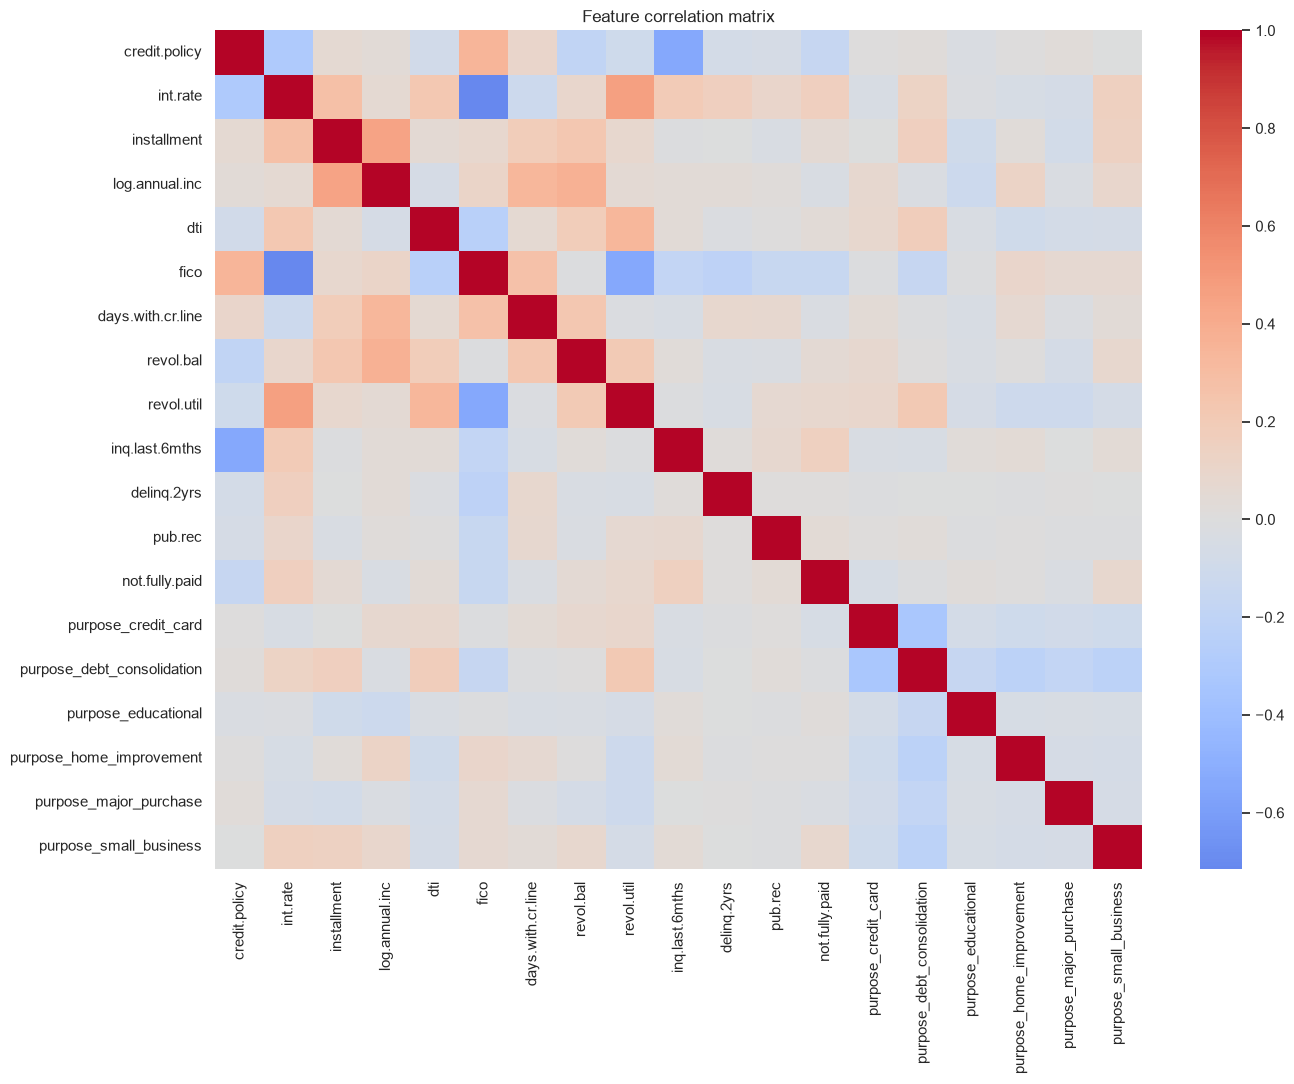

In [10]:
corr_matrix = df_encoded.corr()

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, annot=False, ax=ax)
ax.set_title('Feature correlation matrix')
plt.tight_layout()
plt.show()

In [11]:
# Identify feature pairs (excluding the target) with strong correlation
CORR_THRESHOLD = 0.75

feature_corr = corr_matrix.drop(index='not.fully.paid', columns='not.fully.paid')
upper = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool))

strong_pairs = [
    (col, row, upper.loc[row, col])
    for col in upper.columns
    for row in upper.index
    if pd.notnull(upper.loc[row, col]) and abs(upper.loc[row, col]) > CORR_THRESHOLD
]
print(f'Feature pairs with |corr| > {CORR_THRESHOLD}:')
for a, b, v in strong_pairs:
    print(f'  {a}  <->  {b}   corr={v:.3f}')

to_drop = sorted({b for _, b, _ in strong_pairs})
print('\nColumns dropped:', to_drop if to_drop else 'none — no feature pair exceeded the threshold')

Feature pairs with |corr| > 0.75:

Columns dropped: none — no feature pair exceeded the threshold


In [12]:
df_model = df_encoded.drop(columns=to_drop)
print('Final feature count (excluding target):', df_model.shape[1] - 1)
df_model.columns.tolist()

Final feature count (excluding target): 18


['credit.policy',
 'int.rate',
 'installment',
 'log.annual.inc',
 'dti',
 'fico',
 'days.with.cr.line',
 'revol.bal',
 'revol.util',
 'inq.last.6mths',
 'delinq.2yrs',
 'pub.rec',
 'not.fully.paid',
 'purpose_credit_card',
 'purpose_debt_consolidation',
 'purpose_educational',
 'purpose_home_improvement',
 'purpose_major_purchase',
 'purpose_small_business']

At the standard 0.75 threshold none of the remaining engineered features are redundant — `int.rate` correlates with `fico` as expected (higher risk -> higher rate) but not strongly enough to drop either. This step is kept in the pipeline since it is required, and would prune features automatically if a future data refresh introduces redundant fields.

## 5. Modeling — deep learning with Keras/TensorFlow

In [13]:
X = df_model.drop(columns=['not.fully.paid'])
y = df_model['not.fully.paid']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Train shape:', X_train_scaled.shape, ' Test shape:', X_test_scaled.shape)

Train shape: (7662, 18)  Test shape: (1916, 18)


In [14]:
# Class weights compensate for the ~84/16 imbalance so the minority (default) class isn't ignored
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(class_weights))
print('Class weights:', class_weight_dict)

Class weights: {0: np.float64(0.5952454940957116), 1: np.float64(3.124796084828711)}


In [15]:
model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', keras.metrics.AUC(name='auc'), keras.metrics.Recall(name='recall')],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,225 (16.50 KB)

 Trainable params: 4,033 (15.75 KB)

 Non-trainable params: 192 (768.00 B)

In [16]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_auc', mode='max', patience=10, restore_best_weights=True
)

history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=0,
)
print(f'Training stopped after {len(history.history["loss"])} epochs (early stopping on val_auc).')

Training stopped after 28 epochs (early stopping on val_auc).


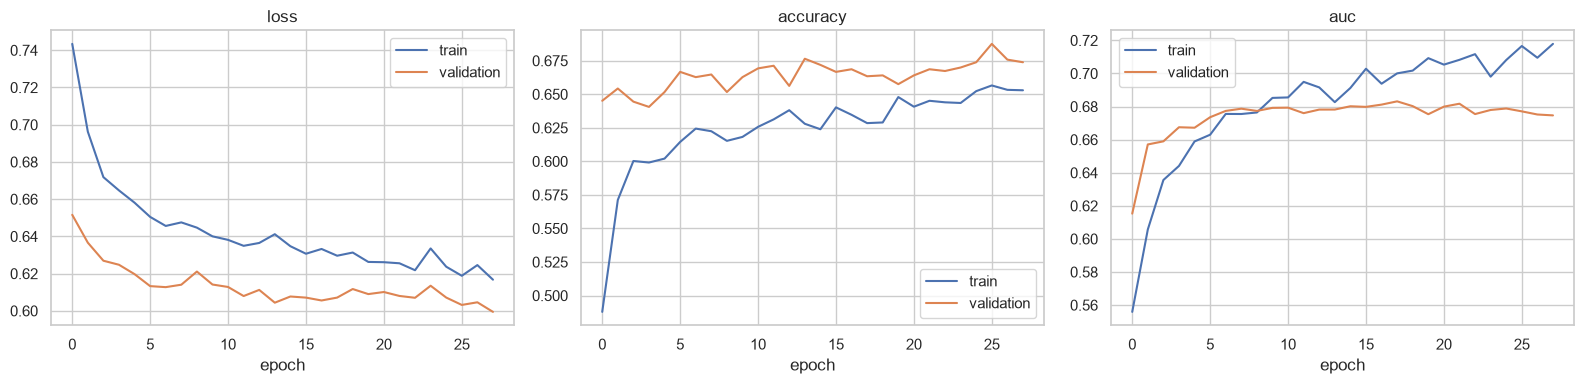

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ['loss', 'accuracy', 'auc']):
    ax.plot(history.history[metric], label='train')
    ax.plot(history.history[f'val_{metric}'], label='validation')
    ax.set_title(metric)
    ax.set_xlabel('epoch')
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Evaluation

In [18]:
y_proba = model.predict(X_test_scaled, verbose=0).ravel()
y_pred = (y_proba >= 0.5).astype(int)

print('Test accuracy:', accuracy_score(y_test, y_pred))
print('Test recall (default class):', recall_score(y_test, y_pred))
print('Test ROC-AUC:', roc_auc_score(y_test, y_proba))
print()
print(classification_report(y_test, y_pred, target_names=['fully_paid', 'default']))

Test accuracy: 0.6597077244258872
Test recall (default class): 0.5830618892508144
Test ROC-AUC: 0.6944487745033536

              precision    recall  f1-score   support

  fully_paid       0.89      0.67      0.77      1609
     default       0.25      0.58      0.35       307

    accuracy                           0.66      1916
   macro avg       0.57      0.63      0.56      1916
weighted avg       0.79      0.66      0.70      1916



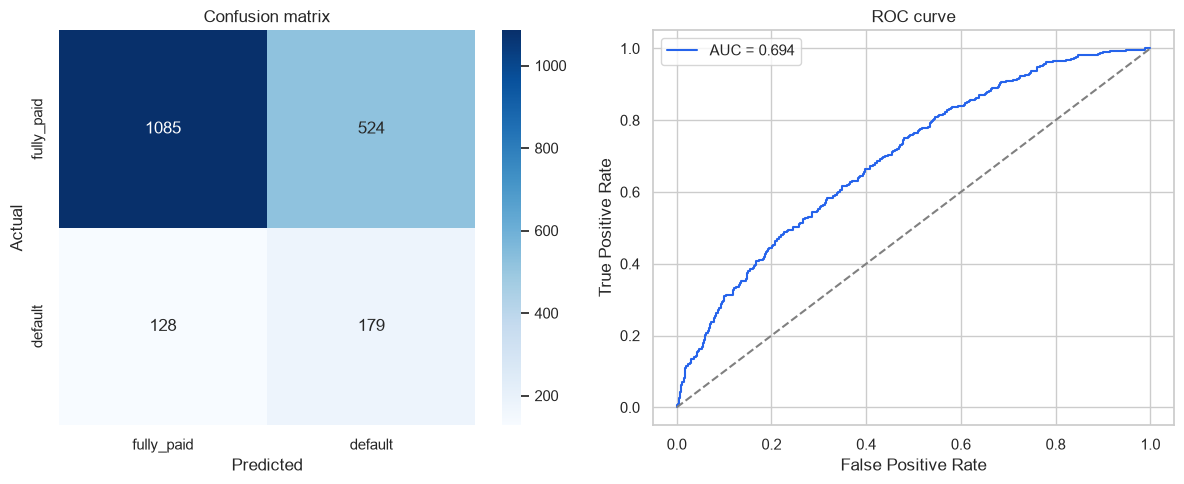

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['fully_paid', 'default'], yticklabels=['fully_paid', 'default'], ax=axes[0])
axes[0].set_title('Confusion matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color='#2563EB', label=f'AUC = {roc_auc_score(y_test, y_proba):.3f}')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title('ROC curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Conclusion

The pipeline completes all four required steps: `purpose` was one-hot encoded (feature transformation), the target's ~84/16 class imbalance and per-feature relationships (FICO, interest rate) were examined (EDA), a correlation pass confirmed no redundant features needed dropping (feature engineering), and a Keras/TensorFlow deep neural network — trained with class weighting and early stopping on validation AUC — produced the final default-risk classifier. ROC-AUC is the primary metric given the class imbalance; accuracy alone would be misleading since predicting "fully paid" for every loan would already score ~84%.